# Семинар 3. Перефразирование

Представьте, мы с вами делаем приложение «Симулятор редактора».

И вот мы пишем статью, а наш редактор предлагает заменить английское *now*. У нас две подсказки: *presently* («в настоящее время») и *instantly* («немедленно»). Какую вы бы выбрали в каждом фрагменте?

1. *…and now president of Information Security Inc.*
2. *Get out of my sight now!*

Это два фрагмента из [Stanford Swords](https://github.com/p-lambda/swords).

Такую задачу называют лексической заменой: меняем одно слово и стараемся сохранить смысл фразы.

Как правильно подобрать слово и когда лучше оставить его как есть?

In [ ]:
%pip install -q "tokenizers==0.22.2" "safetensors>=0.4" "huggingface_hub>=0.30,<1" "nltk==3.9.2" "scikit-learn"

In [ ]:
import gzip
import json
import re
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from IPython.display import display
from safetensors.numpy import load_file
from tokenizers import Tokenizer

## Что можно узнать по двум словам?

Начнём с выражения *a hard task*. И *easy*, и *difficult* легко вспомнить по слову *hard*. Но только одна замена сохранит смысл выражения.

В [SimLex-999: Evaluating Semantic Models With (Genuine) Similarity Estimation](https://aclanthology.org/J15-4004/) есть две отдельные оценки. В `Assoc(USF)` указана сила свободной ассоциации между словами. Её оценивали по тому, какие слова люди называли в ответ на слово-стимул. В `SimLex999` - насколько люди считали значения слов похожими, по шкале от 0 до 10.

<details><summary>Что за название?</summary>

В работе предложен датасет из **999 пар слов** (666 пар существительных, 222 пары глаголов и 111 пар прилагательных) с человеческими оценками сходства значений. SimLex по смыслу читается как сочетание similarity и lexical - "лексическое сходство".

Название отсылает к работе **[WordSim-353 (WS-353)](https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.html)** - это датасет из 353 пар слов. В нём уже участники оценивали общую смысловую связанность слов по шкале от 0 до 10, поэтому высокую оценку могли получить и слова с разными значениями. Например, пара *clothes - closet* («одежда - шкаф»).

> **Как оценивают модель?** `SimLex999` и `Assoc(USF)` описывают свойства пар слов по данным человеческих ответов. Для оценки эмбеддингов в статье сначала вычисляют косинусное сходство векторов каждой пары, затем ранговую корреляцию Спирмена между полученными сходствами и человеческими оценками по всему датасету.

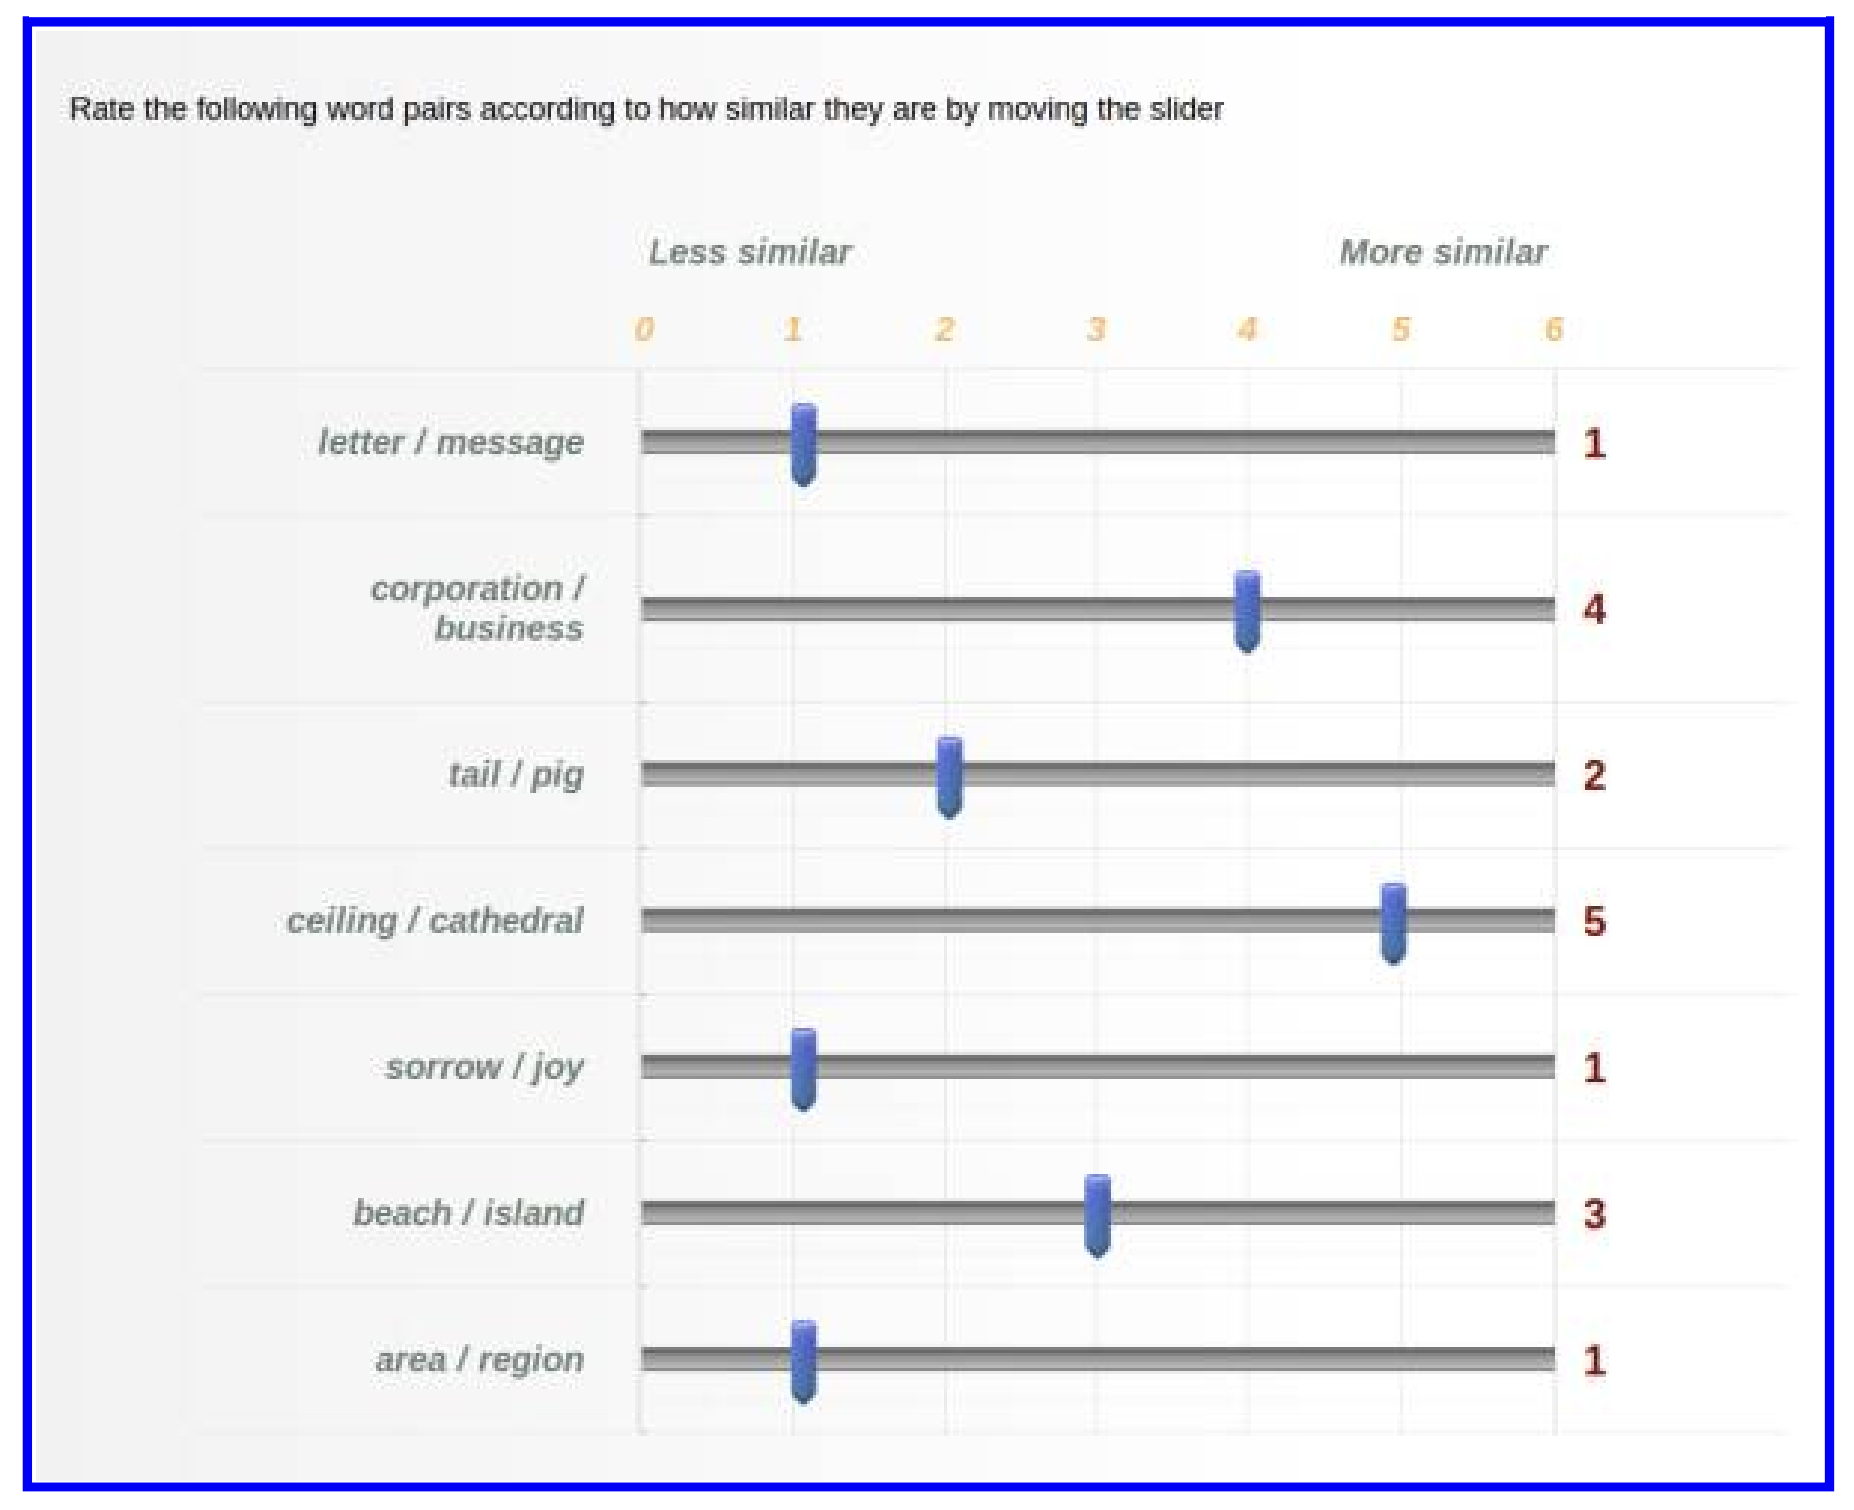

</details>

In [ ]:
with ZipFile(BytesIO(urlopen("https://fh295.github.io/SimLex-999.zip").read())) as archive:
    with archive.open("SimLex-999/SimLex-999.txt") as file:
        pairs = pd.read_csv(file, sep="\t")

focus = (pairs.word1 == "hard") & pairs.word2.isin(["easy", "difficult"])
pairs.loc[focus, ["word1", "word2", "Assoc(USF)", "SimLex999"]]

,word1,word2,Assoc(USF),SimLex999
2,hard,difficult,5.94,8.77
4,hard,easy,5.82,0.95


А теперь посмотрим, какой из двух вариантов окажется ближе к *hard* по косинусу.

Возьмем для этого [POTION-base-2M](https://huggingface.co/minishlab/potion-base-2M) - это небольшая модель со своей особенностью: токенизатор делит слово или фразу на части, а для каждой части в таблице POTION хранится вектор из 64 чисел. В функции `embed` мы усредним эти векторы и разделим результат на его длину. А после уже скалярное произведение двух таких векторов даст нам косинус.

<details><summary>Как обучили POTION?</summary>

<img src="https://raw.githubusercontent.com/MinishLab/model2vec/main/assets/images/logo_v2.png" width="400">

Цитируем:

> This [Model2Vec](https://github.com/MinishLab/model2vec) model is pre-trained using [Tokenlearn](https://github.com/MinishLab/tokenlearn). It is a distilled version of the [baai/bge-base-en-v1.5](https://huggingface.co/BAAI/bge-base-en-v1.5) Sentence Transformer. It uses static embeddings, allowing text embeddings to be computed orders of magnitude faster on both GPU and CPU. It is designed for applications where computational resources are limited or where real-time performance is critical.

[Описание обучения от авторов POTION](https://minish.ai/blog/2024-10-29-tokenlearn-blogpost/).

</details>

In [ ]:
repo = "minishlab/potion-base-2M"
tokenizer = Tokenizer.from_file(hf_hub_download(repo, "tokenizer.json"))
weights = load_file(hf_hub_download(repo, "model.safetensors"))["embeddings"]

def unit(vector):
    return vector / np.linalg.norm(vector)

def embed(text):
    ids = tokenizer.encode(text, add_special_tokens=False).ids
    return unit(weights[ids].mean(axis=0))

hard = pairs.loc[focus, ["word1", "word2", "SimLex999"]].copy()
hard_vector = embed("hard")
hard["Косинус POTION"] = [hard_vector @ embed(word) for word in hard.word2]
hard.round(3)

,word1,word2,SimLex999,Косинус POTION
2,hard,difficult,8.77,0.583
4,hard,easy,0.95,0.179


К *hard* ближе оказалось слово *difficult* (0.583). В выражении *a hard task* этот порядок нам подходит.

Мы ведь могли поставить и другой вопрос: «Какое слово приходит в голову, когда вы слышите *hard*?» Тогда *easy* был бы хорошим ответом. Для редактора важнее другое: после подстановки в предложение смысл должен сохраниться.

Вернемся теперь к двум фразам с *now*: если передать модели только слово, его вектор оба раза будет одним и тем же. А как люди оценили замену?

## Какую замену выбрали люди?

На [SemEval-2007](https://aclanthology.org/S07-1009/) уже участники предлагали свои замены для выделенного слова. Мы возьмём [Swords](https://aclanthology.org/2021.naacl-main.345/) (такой бенчмарк), где для каждого фрагмента уже собран список кандидатов. Эти кандидаты даны в словарной форме: например, для глагола в прошедшем времени разметчик мог одобрить начальную форму глагола.

Давайте глянем на пример из статьи - *said*. Разметчик читает фрагмент и отдельно решает, какую из предложенных замен сам использовал бы в этом месте.

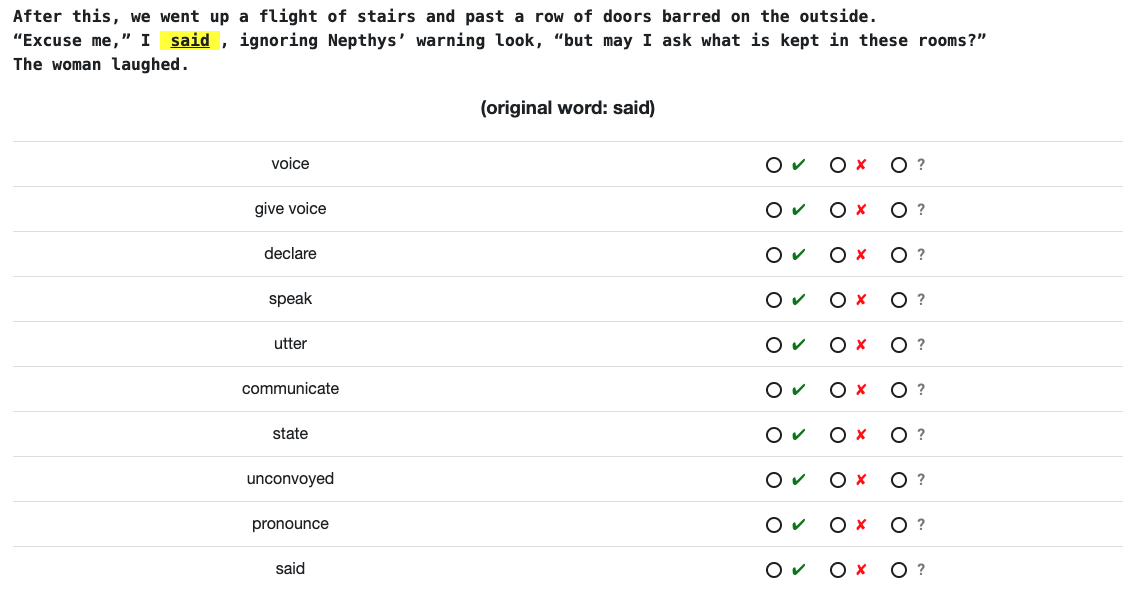

Рис. 3 из [SWORDS : A Benchmark for Lexical Substitution with Improved Data Coverage and Quality](https://aclanthology.org/2021.naacl-main.345.pdf#page=14).

Теперь откроем часть `dev` и найдём оба вхождения *now*. Квадратными скобками отметим слово, которое оценивали разметчики.

[Данные Swords](https://github.com/p-lambda/swords#downloading-the-swords-benchmark)

In [ ]:
# лучше четко определить версию
revision_swords = "04ca75370d0ce098a7f4db68240fc8e79a4f7b3b"

def load_swords(split):
    url = f"https://raw.githubusercontent.com/p-lambda/swords/{revision_swords}/assets/parsed/swords-v1.1_{split}.json.gz"
    with urlopen(url) as response, gzip.GzipFile(fileobj=response) as file:
        return json.load(file)

def get_examples(swords):
    examples = []
    for number, (target_id, item) in enumerate(swords["targets"].items(), 1):
        text = swords["contexts"][item["context_id"]]["context"]
        word = item["target"]
        start = item["offset"]
        left, right = text[:start], text[start + len(word):]

        # offset указывает, какое именно вхождение слова выделено
        excerpt = " ".join(left.split()[-8:] + [f"[{word}]"] + right.split()[:8])
        examples.append({"id": target_id, "example": number, "word": word,
                         "lemma": item["extra"]["coinco_lemma"], "excerpt": excerpt,
                         "left": left, "right": right})

    return pd.DataFrame(examples).set_index("id")

swords = load_swords("dev")
examples = get_examples(swords)
now = examples.loc[examples.word == "now"]
for row in now.itertuples():
    print(row.example, row.excerpt)

80 staffer at the federal National Security Agency and [now] president of Information Security Inc., Silver Spring, Md.
250 Fools! Get out of my sight [now] – unless you know how to put it


У разметчиков было три варианта ответа: `TRUE`, `FALSE` и `UNSURE`. В столбце `yes` посчитаем ответы `TRUE`, в `votes` - все ответы, включая `UNSURE`. Считаем замену подходящей, если за неё проголосовало больше половины ответивших. Например, 6 голосов из 10 достаточно, а 5 из 10 - уже нет.

Голоса относятся к конкретной паре «фрагмент и замена». В одном фрагменте большинство может одобрить сразу несколько замен.

Число голосов различается: сначала авторы собирали три ответа, а кандидаты, получившие хотя бы один положительный голос, отправлялись на дополнительную оценку.

Из списка уберем само выделенное слово и его словарную форму. Посмотрим, сколько человек одобрили каждую из двух замен для *now*.

In [ ]:
def get_candidates(swords, examples):
    rows = []
    for substitute_id, item in swords["substitutes"].items():
        votes = swords["substitute_labels"][substitute_id]
        rows.append({"id": item["target_id"], "candidate": item["substitute"],
                     "yes": votes.count("TRUE"), "votes": len(votes)})

    choices = pd.DataFrame(rows).join(examples[["example", "word", "lemma"]], on="id")
    choices["accepted"] = 2 * choices.yes > choices.votes

    # подсказка должна отличаться от исходного слова и его словарной формы
    same_word = choices.candidate.str.casefold() == choices.word.str.casefold()
    same_lemma = choices.candidate.str.casefold() == choices.lemma.str.casefold()
    return choices.loc[~same_word & ~same_lemma].copy()

choices = get_candidates(swords, examples)
two_options = choices.id.isin(now.index) & choices.candidate.isin(["presently", "instantly"])
choices.loc[two_options, ["example", "word", "candidate", "yes", "votes"]].sort_values(["example", "candidate"])

,example,word,candidate,yes,votes
5094,80,now,instantly,0,3
5097,80,now,presently,8,10
15084,250,now,instantly,9,10
15093,250,now,presently,0,3


**Задание 1. Что скажет редактор?** В первом тексте *now* указывает на нынешнюю должность, а во втором человек требует уйти сию минуту. Какую из двух замен поставит выше POTION в каждом тексте, если мы передадим ей только слово *now*? Сформулируйте прогноз, затем запустите ячейку.

**Ваш ответ:**

In [ ]:
for candidate in ["presently", "instantly"]:
    print(f"now / {candidate}: {embed('now') @ embed(candidate):.3f}")

now / presently: 0.512
now / instantly: 0.605


У *instantly* косинус выше в обоих случаях. Для первого предложения это расходится с мнением разметчиков.

Пока мы выбирали из двух слов. В полном списке есть и другие варианты, например *just now*. Что изменится, если добавить в расчёт слова из самого фрагмента?

## Поможет ли ближайший контекст?

У нас есть предположение: возможно, замену легче выбрать, если учесть слова рядом. Возьмём до пяти слов с каждой стороны от выделенного слова и соберём их в один вектор. Для каждого кандидата усредним два косинуса: со словом и с его окружением. Посмотрим, что попадёт в окно вокруг *now*.

<details><summary>Как именно посчитаем оценку кандидата?</summary>

Обозначим через $w$ выделенное слово, через $c$ - кандидата, через $C$ - текст окна. Берём до пяти слов слева и до пяти справа от нужного вхождения. Само вхождение пропускаем. Обе половины соединяем в одну строку и один раз вызываем `embed`. Поэтому в вектор окна входит каждый субтокен POTION. Если слово разбито на три части, в среднем участвуют все три строки таблицы.

$$s_{\rm word}(c)=\cos(e(c),e(w)), \qquad s_{\rm ctx}(c)=\cos(e(c),e(C)).$$

Здесь $e$ - наша функция `embed`. В варианте «только слово» сортируем кандидатов по $s_{\rm word}$. В варианте с контекстом сортируем по среднему $(s_{\rm word}+s_{\rm ctx})/2$. В обоих случаях лучшим считаем кандидата с наибольшей оценкой.

> Два источника информации использовали и в работе [A Simple Word Embedding Model for Lexical Substitution](https://aclanthology.org/W15-1501/). В статье совместимость кандидата с контекстом оценивали по синтаксическим связям. А достаточно ли слов по соседству вообще?

</details>

In [ ]:
def context_window(left, right, width=5):
    before = re.findall(r"[a-z]+", left.lower())
    after = re.findall(r"[a-z]+", right.lower())
    return " ".join(before[-width:] + after[:width])

examples["window"] = [context_window(row.left, row.right) for row in examples.itertuples()]
for text in examples.loc[now.index, "window"]:
    print(text)

federal national security agency and president of information security inc
get out of my sight unless you know how to


In [ ]:
word_vectors = {word: embed(word) for word in choices.word.unique()}
candidate_vectors = {word: embed(word) for word in choices.candidate.unique()}
window_vectors = {idx: embed(text) for idx, text in examples.window.items()}

choices["word_score"] = [candidate_vectors[c] @ word_vectors[w]
                         for c, w in zip(choices.candidate, choices.word)]
choices["context_score"] = [candidate_vectors[c] @ window_vectors[idx]
                            for c, idx in zip(choices.candidate, choices.id)]
choices["mixed_score"] = (choices.word_score + choices.context_score) / 2

score_columns = ["example", "candidate", "word_score", "context_score", "mixed_score"]
choices.loc[two_options, score_columns].sort_values(["example", "candidate"]).round(3)

,example,candidate,word_score,context_score,mixed_score
5094,80,instantly,0.605,-0.154,0.225
5097,80,presently,0.512,-0.066,0.223
15084,250,instantly,0.605,0.487,0.546
15093,250,presently,0.512,0.368,0.440


Сравните две строки для *instantly*. Его близость к *now* одинакова.

В приказе «уйди сейчас» косинус кандидата с окном равен 0.487, а во фразе о нынешней должности он отрицательный (-0.154). После усреднения в примере 80 почти ничья: 0.225 и 0.223. Но - порядок этих двух слов всё ещё расходится с голосами людей.

Теперь вернём **всех кандидатов**. Для каждого из 370 примеров сохраним первую подсказку и её отрыв от второй.

Сначала оценим выбор из списка на 317 примерах, где хотя бы одна замена получила большинство голосов.

Если большинство одобрило первую подсказку, засчитываем попадание.

In [ ]:
def top_choice(frame, score):
    ranked = frame.sort_values(["id", score, "candidate"], ascending=[True, False, True]).copy()
    next_score = ranked.groupby("id")[score].shift(-1)
    ranked["gap"] = ranked[score] - next_score
    return ranked.drop_duplicates("id").set_index("id")

baseline = top_choice(choices, "word_score")
with_context = top_choice(choices, "mixed_score")
has_answer = choices.groupby("id").accepted.any()
evaluation_ids = has_answer.index[has_answer]

for name, first in [("Только слово", baseline), ("С контекстом", with_context)]:
    hits = first.loc[evaluation_ids, "accepted"]
    print(f"{name}: {hits.sum()} из {len(hits)} ({hits.mean():.1%})")

Только слово: 121 из 317 (38.2%)
С контекстом: 112 из 317 (35.3%)


С контекстом получилось 112 попаданий вместо 121.

Для каждого фрагмента сравним результаты двух способов. Строки показывают, одобрили ли люди подсказку по одному слову, столбцы - подсказку с контекстом.

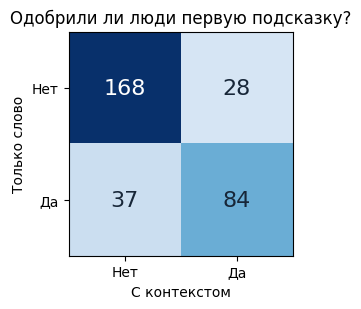

In [ ]:
outcomes = pd.DataFrame({"Только слово": baseline.accepted, "С контекстом": with_context.accepted})
counts = pd.crosstab(outcomes.loc[evaluation_ids, "Только слово"],
                     outcomes.loc[evaluation_ids, "С контекстом"]).reindex(
                         index=[False, True], columns=[False, True], fill_value=0)

fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.imshow(counts, cmap="Blues", vmin=0, vmax=counts.to_numpy().max())
for i in range(2):
    for j in range(2):
        value = counts.iloc[i, j]
        ax.text(j, i, str(value), ha="center", va="center", fontsize=16,
                color="white" if value > counts.to_numpy().max() / 2 else "#172638")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Нет", "Да"], yticklabels=["Нет", "Да"],
       xlabel="С контекстом", ylabel="Только слово", title="Одобрили ли люди первую подсказку?")
fig.tight_layout()
plt.show()

Нас интересуют две группы из этой таблицы. В 28 фрагментах контекст помог выбрать одобренную замену, а в 37 удачная замена уступила место неудачной. Отсюда и разница в девять попаданий.

Посмотрим по одному примеру из каждой группы.

**Задание 2. Гляньте на два решения.** В примерах 295 и 337 найдите слово или выражение, от которого зависит смысл. Что из этого попало в окно? Сопоставьте два предложенных слова с фрагментом и с голосами разметчиков.

In [ ]:
def inspect_example(number):
    row = examples.loc[examples.example == number].iloc[0]
    print(row.excerpt)
    print("Окно:", row.window)
    result = pd.DataFrame([baseline.loc[row.name], with_context.loc[row.name]],
                          index=["Только слово", "С контекстом"])
    display(result[["candidate", "yes", "votes"]])

for number in [295, 337]:
    inspect_example(number)

it have anything to do with why your [head] is shaved?” “It was part of the price
Окно: to do with why your is shaved it was part


,candidate,yes,votes
Только слово,heading,0,3
С контекстом,scalp,6,10


jubilant. He knew the war would soon be [over] and he would be heading home. A yearof
Окно: the war would soon be and he would be heading


,candidate,yes,votes
Только слово,conclude,7,10
С контекстом,above,0,3


In [ ]:
changed_outcome = outcomes["Только слово"] != outcomes["С контекстом"]
numbers = sorted(examples.loc[changed_outcome, "example"])
print("Ещё несколько примеров:", numbers[::8])
my_example = 80
inspect_example(my_example)

Ещё несколько примеров: [8, 38, 80, 100, 154, 228, 275, 320, 363]
staffer at the federal National Security Agency and [now] president of Information Security Inc., Silver Spring, Md.
Окно: federal national security agency and president of information security inc


,candidate,yes,votes
Только слово,just now,0,3
С контекстом,current,8,10


Помните фразу про нынешнего президента из примера 80? Из двух слов *presently* и *instantly* модель даже с контекстом выбирала *instantly*. А в полном списке нашлась ещё одна замена. По одному слову первой шла *just now* (0 голосов из 3), с контекстом на первое место вышла *current* (8 из 10).

**Разбор:**

<details><summary>Разбор примеров</summary>

В примере 295 у человека выбрита голова. При сравнении отдельных слов первым оказалось *heading* («заголовок»), за него никто не проголосовал. В окне есть *shaved*. С учётом окна наверх поднялось *scalp* («кожа головы»), 6 голосов из 10. Возможно, подсказкой послужило *shaved*.

В примере 337 сочетание *would soon be over* означает, что война скоро закончится. Разметчики приняли *conclude* и отклонили *above*. Модель сравнивает замену отдельно с вектором *over* и с усреднённым окружением. В этом случае добавление окна подняло неподходящее *above*.

</details>

Проверим догадку про *shaved*?

Удалим одно слово только из **входа модели**.

In [ ]:
number = 295
hidden_word = "shaved"
example = examples.loc[examples.example == number].iloc[0]
tokens = example.window.split()
short_window = " ".join(word for word in tokens if word != hidden_word.lower())
print("Было:", example.window)
print("Стало:", short_window)

trial = choices.loc[choices.example == number].copy()
window_vector = embed(short_window)
trial["short_context_score"] = [candidate_vectors[c] @ window_vector for c in trial.candidate]
trial["without_word"] = (trial.word_score + trial.short_context_score) / 2
for title, score in [("Полное окно", "mixed_score"), ("Убрали слово", "without_word")]:
    print(title)
    display(trial.nlargest(3, score)[["candidate", score, "yes", "votes"]].round(3))

Было: to do with why your is shaved it was part
Стало: to do with why your is it was part
Полное окно


,candidate,mixed_score,yes,votes
18141,scalp,0.345,6,10
18181,hair,0.335,6,10
18175,skull,0.294,6,10


Убрали слово


,candidate,without_word,yes,votes
18183,top part of an animate body,0.237,0,3
18111,top part,0.228,0,3
18110,heading,0.227,0,3


После удаления *shaved* первыми стали три замены, за которые в исходном тексте никто не проголосовал. В этом фрагменте одного слова оказалось достаточно, чтобы сменилась вся первая тройка.

Для следующего опыта возьмём вариант «только слово». На этой выборке он дал 121 попадание, а с окном получилось 112.

## Когда лучше оставить текст как есть?

Наш гипотетический редактор двигается по тексту: он может подчеркнуть слово и предложить замену, а может и пропустить.

> Когда мы пропускаем?

Попробуем простое правило. Сначала сравним по косинусу исходное слово и предложенную замену.

У нас уже есть список замен с оценками. Из оценки первой вычтем оценку второй. Если разница меньше порога, пропустим подсказку. И тут есть что проверить: даже большой отрыв возможен у слова, которое совсем не подходит к фразе.

Проверим правило на всех 370 фрагментах. Для каждого из них мы знаем, какие замены одобрили разметчики. В 53 фрагментах ни один вариант не набрал большинства голосов. Их тоже важно учесть: редактор вполне может предложить замену там, где людям не подошла ни одна. Сначала решим по оценкам модели, что показать, а затем сверим показанные подсказки с голосами людей.

<details><summary>Что означают отрыв и охват?</summary>

У слова *now* первыми идут *just now* (0.874) и *here and now* (0.854). Отрыв около 0.020. С порогом 0.05 редактор такую подсказку пропустит.

Охват показывает, в какой доле фрагментов появится подсказка. Долю одобренных среди показанных считаем только по тем фрагментам, где подсказка появилась. Если редактор пропустил все фрагменты, эта доля не определена.

</details>

**Задание 3. При каком отрыве показывать подсказку?** При нулевом пороге редактор предлагает замену в каждом фрагменте. Для пробного запуска мы готовы показывать подсказки реже, но хотим сохранить хотя бы половину удачных подсказок этого режима. Из порогов в таблице выберите тот, при котором выполнится это условие и пользователи увидят меньше всего неудачных замен.

А если захотим сохранить три четверти удачных подсказок, какой порог тогда выберем?

In [ ]:
def hint_report(first, min_gap):
    shown = first.loc[first.gap >= min_gap]
    useful = int(shown.accepted.sum())
    return {"Порог": min_gap, "Показали": len(shown), "Полезных": useful,
            "Не подошли": len(shown) - useful,
            "Пропустили": len(first) - len(shown), "Охват": len(shown) / len(first),
            "Доля полезных среди показанных": shown.accepted.mean()}

thresholds = [0, 0.02, 0.05, 0.10, 0.20]
report = pd.DataFrame([hint_report(baseline, threshold) for threshold in thresholds])
report.set_index("Порог").round(3)

,Показали,Полезных,Не подошли,Пропустили,Охват,Доля полезных среди показанных
Порог,,,,,,
0.00,370,121,249,0,1.000,0.327
0.02,290,98,192,80,0.784,0.338
0.05,211,75,136,159,0.570,0.355
0.10,116,45,71,254,0.314,0.388
0.20,46,12,34,324,0.124,0.261


**Ваш ответ:**

<details><summary>Разбор выбора порога</summary>

Без порога большинство одобрило 121 подсказку. Чтобы сохранить хотя бы половину, нужно оставить минимум 61. Среди проверенных порогов подходит 0.05: остаются 75 удачных подсказок и 136 неудачных. По сравнению с показом в каждом фрагменте мы убрали 113 неудачных показов ценой 46 удачных. При 0.10 остаются всего 45 удачных подсказок.

Если хотим сохранить три четверти, нужно оставить хотя бы 91 удачную подсказку. Тогда из таблицы выберем 0.02. Он сохраняет 98 удачных подсказок, при этом 57 неудачных показов исчезают. Теряем 23 удачных.

Посмотрите и на последние две строки. При 0.10 разметчики одобрили 45 из 116 показанных замен (38.8%), при 0.20 - 12 из 46 (26.1%). На этой выборке увеличение отрыва не всегда повышает долю удачных среди показанных. Порог мы выбрали на этих примерах. Для проверки понадобится новая подборка с разметкой.

</details>

### А если проверить все пороги?

В первой таблице за 0.05 сразу шёл порог 0.10. Сколько ещё неудачных показов можно убрать, если проверить все отрывы между ними?

В scikit-learn для бинарного классификатора порог можно подобрать через `TunedThresholdClassifierCV`. У нас уже посчитан отрыв и известно, одобрили ли разметчики первую замену. Передадим эти два столбца в `precision_recall_curve`.

> Можно погрузиться вот сюда при желании: [выбор порога в scikit-learn](https://scikit-learn.org/stable/modules/classification_threshold.html)

При пороге 0.05 показали 211 подсказок, из них 75 удачных. Доля удачных среди показанных (**precision**) равна 75/211. А всего удачных первых замен было 121, так что мы сохранили 75/121 из них (**recall**). Нужна хотя бы половина. Возьмём наибольший порог, при котором это условие ещё выполняется: чем выше порог, тем меньше подсказок пройдёт отбор.

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, cutoffs = precision_recall_curve(baseline.accepted, baseline.gap)

# у последней точки precision и recall нет своего порога
curve = pd.DataFrame({"Порог": cutoffs, "precision": precision[:-1], "recall": recall[:-1]})
fine_gap = curve.loc[curve["recall"] >= 0.5, "Порог"].max()

dev_report = pd.DataFrame([hint_report(baseline, gap) for gap in [0.05, fine_gap]])
dev_report["Сохранили удачных"] = dev_report["Полезных"] / baseline.accepted.sum()
dev_report.round(4)

,Порог,Показали,Полезных,Не подошли,Пропустили,Охват,Доля полезных среди показанных,Сохранили удачных
0,0.0500,211,75,136,159,0.5703,0.3555,0.6198
1,0.0731,151,61,90,219,0.4081,0.4040,0.5041


Получилось примерно 0.0731. Осталась 61 удачная подсказка из 121 - как раз проходим по условию. При этом неудачных показов стало 90 вместо 136. Запомним оба порога для проверки на новых фразах.

### Если показывать реже, ошибок среди подсказок станет меньше?

Посмотрим на те же 211 показов при пороге 0.05 с другой стороны. Всего у нас 370 фрагментов, так что подсказку увидят в 211/370 случаев (57%). Это **охват** (*coverage*). Среди этих 211 подсказок разметчики отклонили 136. Значит, **доля ошибок среди показанных** (*selective risk*) равна 136/211 (64.5%). На графике по горизонтали отложим охват, по вертикали - долю ошибок. Каждая точка отвечает одному порогу.

Идея озвучена в работе [Selective Classification for Deep Neural Networks](https://proceedings.neurips.cc/paper/2017/hash/4a8423d5e91fda00bb7e46540e2b0cf1-Abstract.html).

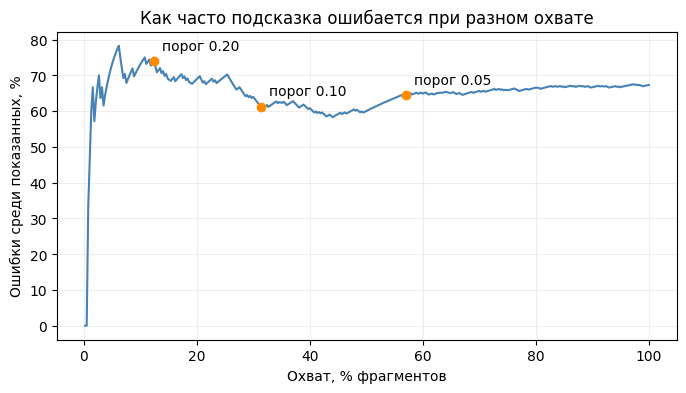

In [ ]:
curve["Охват"] = [(baseline.gap >= gap).mean() for gap in curve["Порог"]]
curve["Доля ошибок"] = 1 - curve["precision"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(100 * curve["Охват"], 100 * curve["Доля ошибок"], color="steelblue")
for gap in [0.05, 0.10, 0.20]:
    row = hint_report(baseline, gap)
    x = 100 * row["Охват"]
    y = 100 * row["Не подошли"] / row["Показали"]
    ax.scatter(x, y, color="darkorange", zorder=3)
    ax.annotate(f"порог {gap:.2f}", (x, y), xytext=(6, 8), textcoords="offset points")
ax.set(xlabel="Охват, % фрагментов", ylabel="Ошибки среди показанных, %",
       title="Как часто подсказка ошибается при разном охвате")
ax.grid(alpha=0.2)
plt.show()

Прочитаем график справа налево: постепенно поднимаем порог и показываем всё меньше подсказок. При переходе с 0.10 на 0.20 охват упал с 31% до 12%, а доля ошибок среди показанных **выросла** с 61% до 74%. Почему так может быть? Большой отрыв говорит, что первое слово обошло второе. Оба при этом могут плохо подходить к фразе.

Откроем отложенную часть Swords. Снова сравним показ в каждом фрагменте с двумя порогами, которые мы выбрали на dev. При каком из них на новых фразах сохранится хотя бы половина удачных подсказок?

In [ ]:
test_swords = load_swords("test")
test_examples = get_examples(test_swords)
test_choices = get_candidates(test_swords, test_examples)

words_to_score = set(test_choices.word) | set(test_choices.candidate)
vectors = {word: embed(word) for word in words_to_score}
test_choices["word_score"] = [vectors[w] @ vectors[c] for w, c in zip(test_choices.word, test_choices.candidate)]
test_first = top_choice(test_choices, "word_score")

test_report = pd.DataFrame([hint_report(test_first, gap) for gap in [0, 0.05, fine_gap]])
test_report["Сохранили удачных"] = test_report["Полезных"] / test_first.accepted.sum()
test_report.round(4)

,Порог,Показали,Полезных,Не подошли,Пропустили,Охват,Доля полезных среди показанных,Сохранили удачных
0,0.0000,762,229,533,0,1.0000,0.3005,1.0000
1,0.0500,405,134,271,357,0.5315,0.3309,0.5852
2,0.0731,296,107,189,466,0.3885,0.3615,0.4672


При пороге 0.05 сохранились 134 из 229 удачных подсказок (58.5%). При 0.0731 остались 107 (46.7%): на dev половина едва набралась, на новых фразах уже не хватило. А как это выглядит со стороны читателя? Даже при 0.05 из 405 показанных замен одобрили только 134. Я бы пока оставила пользователю возможность запросить варианты по своему желанию.

**Для обсуждения.** Теперь у нас два каталога товаров. Для каждой карточки из первого модель находит несколько похожих карточек во втором. Как решить, какие совпадения подтверждать автоматически, а какие отправлять человеку? Что нужно разметить, если части товаров во втором каталоге вообще нет?

<details><summary>Как проверить правило на карточках?</summary>

Для выборки карточек укажем верную пару во втором каталоге или отметим, что товара там нет. Так при проверке обнаружится и случай, когда модель предложила похожий товар, а верная пара даже не попала в список. Для нескольких порогов на этих данных посчитаем, сколько неверных пар подтвердилось автоматически и сколько карточек ушло бы на ручную проверку. Выбрать режим помогут две вещи: насколько дорого обойдётся неверное объединение и сколько карточек команда успевает проверить.

</details>

## Какие товары можно сопоставить автоматически?

Допустим, мы хотим сравнить цены в двух магазинах. Нам нужен один и тот же товар в той же комплектации. Вот у одного проигрывателя в названии 400 дисков, у другого 300. Названия похожи, а сравнивать их цены как цены одного товара было бы ошибкой.

Давайте проверим это на каталогах [Abt и Buy](https://dbs.uni-leipzig.de/research/projects/benchmark-datasets-for-entity-resolution).

Авторы собрали названия и список пар, в которых магазины продают один и тот же товар. Для каждой карточки Abt возьмём два ближайших названия из Buy и посчитаем знакомый отрыв. Сверяться будем по идентификаторам товаров в эталоне. В полном каталоге Buy у каждого товара из Abt есть пара. А в жизни поставщик вполне может прислать неполную выгрузку.

Смоделируем? Уберём карточки Buy, у которых идентификатор делится на пять. Из 1092 карточек останется 836. По исходному эталону мы сможем проверить, у каких товаров Abt теперь вообще нет пары.

In [ ]:
url = "https://dbs.uni-leipzig.de/files/datasets/Abt-Buy.zip"
with ZipFile(BytesIO(urlopen(url).read())) as archive:
    abt = pd.read_csv(archive.open("Abt.csv"), encoding="latin1")
    buy = pd.read_csv(archive.open("Buy.csv"), encoding="latin1")
    matches = pd.read_csv(archive.open("abt_buy_perfectMapping.csv"))

buy = buy.loc[buy.id % 5 != 0].reset_index(drop=True)
available_matches = matches.loc[matches.idBuy.isin(buy.id)]

# в каждой строке косинусы одной карточки Abt со всеми карточками Buy
similarities = np.stack(abt.name.map(embed)) @ np.stack(buy.name.map(embed)).T
nearest = np.argsort(-similarities, axis=1, kind="stable")[:, :2]
first, second = nearest.T
rows = np.arange(len(abt))
known_pairs = set(zip(available_matches.idAbt, available_matches.idBuy))

catalog = pd.DataFrame({
    "id": abt.id,
    "Abt": abt.name,
    "Buy": buy.name.to_numpy()[first],
    "gap": similarities[rows, first] - similarities[rows, second],
    "Есть пара": abt.id.isin(available_matches.idAbt),
    "accepted": [(a, b) in known_pairs for a, b in zip(abt.id, buy.id.to_numpy()[first])],
})
print("Карточек Abt без пары в выгрузке:", (~catalog["Есть пара"]).sum())

Карточек Abt без пары в выгрузке: 253


Как выбрать порог для каталога? Допустим, для сравнения цен команда готова автоматически связывать товары, если хотя бы 90 из 100 таких совпадений верны. Среди режимов, которые выполняют это условие, хотим как можно меньше оставлять на ручную проверку.

Возьмём для выбора карточки Abt с чётным идентификатором, остальные отложим. Справочник Buy в обоих случаях один и тот же. В таблицу передаём те же два столбца, что и для редактора: `gap` с отрывом первой карточки от второй и `accepted` с результатом сверки. Какой режим вы бы взяли по этой таблице?

In [ ]:
catalog_dev = catalog.loc[catalog.id % 2 == 0]
catalog_test = catalog.loc[catalog.id % 2 == 1]
catalog_thresholds = [0, 0.05, 0.10, 0.15, 0.20, 0.25]
catalog_columns = {"Показали": "Автоматически", "Полезных": "Верных пар",
                   "Не подошли": "Ошибок", "Пропустили": "Вручную",
                   "Доля полезных среди показанных": "Доля верных среди автоматических"}

catalog_report = pd.DataFrame([hint_report(catalog_dev, gap) for gap in catalog_thresholds])
catalog_report.rename(columns=catalog_columns).set_index("Порог").round(3)

,Автоматически,Верных пар,Ошибок,Вручную,Охват,Доля верных среди автоматических
Порог,,,,,,
0.00,551,318,233,0,1.000,0.577
0.05,264,210,54,287,0.479,0.795
0.10,168,144,24,383,0.305,0.857
0.15,96,86,10,455,0.174,0.896
0.20,52,49,3,499,0.094,0.942
0.25,29,27,2,522,0.053,0.931


При пороге 0.15 верны 86 из 96 автоматических совпадений. Совсем чуть-чуть не хватило до 90%. А дальше есть два варианта: при 0.20 верны 49 из 52, при 0.25 верны 27 из 29. Оба подходят, но первый оставляет меньше ручной работы. Зафиксируем 0.20. На второй части посмотрим, какие карточки всё-таки объединились ошибочно. Была ли у каждого из этих товаров правильная пара в нашей выгрузке?

In [ ]:
catalog_gap = 0.20
check = pd.DataFrame([hint_report(catalog_test, gap) for gap in [0, catalog_gap]])
display(check.rename(columns=catalog_columns).set_index("Порог").round(3))

decisions = catalog_test.copy()
decisions["Решение"] = np.where(decisions.gap >= catalog_gap, "связать", "проверить вручную")
# выведем все ошибочные автоматические совпадения
errors = decisions.loc[(decisions["Решение"] == "связать") & ~decisions.accepted]
with pd.option_context("display.max_colwidth", None):
    display(errors.set_index("id")[["Abt", "Buy", "gap", "Есть пара"]].rename_axis("id Abt").round(3))

,Автоматически,Верных пар,Ошибок,Вручную,Охват,Доля верных среди автоматических
Порог,,,,,,
0.0,530,339,191,0,1.000,0.64
0.2,67,65,2,463,0.126,0.97


,Abt,Buy,gap,Есть пара
id Abt,,,,
27965,LG Titanium Bottom-Freezer Refrigerator - LRBP1031TT,LG Electronics LRBP1031W 10 Cu. Ft. Refrigerator,0.222,True
37907,Sharp AQUOS Blu Ray Disc Player In Black And Silver - BDHP21U,Sharp AQUOS BD-HP50U Blu-ray Disc Player,0.216,False


На отложенных карточках при пороге 0.20 автоматически связали 67 пар, из них 65 верны (97%). Это выше наших 90%. Теперь вопрос в том, успеем ли мы проверить вручную оставшиеся 463 карточки из 530.

Давайте посмотрим на две ошибки. У холодильника LG в выгрузке есть правильная пара, а модель выбрала другой вариант с похожей маркировкой. У плеера Sharp в нашей сокращённой выгрузке не осталось ни одной пары из эталона, а система всё равно связала его с другим плеером. В обоих случаях отрыв больше 0.20.

Если поменяется поставщик, стоит заново разметить выборку его карточек, включая товары без пары. Тогда сможем оценить и число ошибочных объединений, и размер очереди на проверку.

## Дополнительно. А WordNet нам поможет?

В самом начале занятия мы сравнили две пары из SimLex. Теперь возьмём все 999 и проверим, приблизятся ли оценки модели к человеческим, если добавить связи из словаря.

> В *a smart student* слово *smart* означает «умный», а в *Don’t get smart with me* - «дерзкий».

Попробуем изменить сам вектор *smart*?

В [WordNet](https://wordnet.princeton.edu/) слова собраны в группы по значениям. Такую группу называют **синсетом**. Соединим слова из SimLex ребром, если у них есть общий синсет.

Если два слова составляют одну из проверяемых пар SimLex, уберём прямое ребро между ними. Иначе мы сами подтянули бы их векторы друг к другу, а потом измерили бы сходство на той же паре.

Сделаем один шаг [ретрофиттинга](https://aclanthology.org/N15-1184/): для каждого слова поровну смешаем его исходный вектор POTION и средний вектор его соседей.

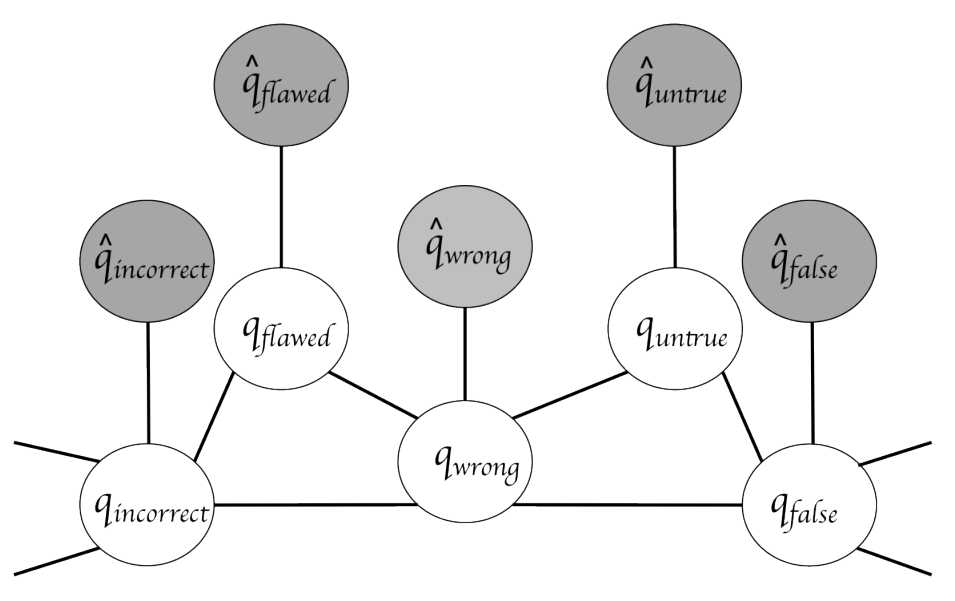

Что на схеме? Серый узел - это исходный вектор слова, белый - вектор, который можно сдвинуть. Например, белый узел *wrong* связан сверху со своим исходным вектором, а по сторонам - с соседями *incorrect*, *flawed*, *untrue* и *false*. Это Рис. 1 из [Retrofitting Word Vectors to Semantic Lexicons](https://aclanthology.org/N15-1184.pdf#page=2).

<details><summary>Ретрофиттинг?</summary>

Пусть $\hat q_i$ - исходный вектор слова, $q_i$ - его обновляемый вектор, а $N(i)$ - соседи слова в графе. В исходном алгоритме $\alpha_i$ задаёт вес исходного вектора, $\beta_{ij}$ - вес связи с соседом $j$. На каждом шаге берем взвешенное среднее:

$$q_i \leftarrow \frac{\alpha_i\hat q_i+\sum_{j\in N(i)}\beta_{ij}q_j}{\alpha_i+\sum_{j\in N(i)}\beta_{ij}}.$$

В статье обновления повторяют. В нашей ячейке будет всего один шаг: половину веса отдаём исходному вектору, вторую половину поровну делим между его соседями. Все векторы соседей берём из `potion`, результат записываем в `adapted` и приводим к единичной длине.

> Например, для слова с тремя соседями вес каждого соседа до нормировки равен $1/6$.

</details>

Сравним, в каком порядке располагаются пары по оценкам людей и по косинусу. Для этого посчитаем корреляцию Спирмена: чем она ближе к 1, тем лучше совпадает порядок.

In [ ]:
from collections import defaultdict
from itertools import combinations

import nltk
from nltk.corpus import wordnet as wn

nltk.download("wordnet", quiet=True)
words = sorted(set(pairs.word1) | set(pairs.word2))
by_sense = defaultdict(set)
for word in words:
    for sense in wn.synsets(word):
        by_sense[sense].add(word)

edges = set()
for group in by_sense.values():
    edges.update(combinations(sorted(group), 2))
test_edges = {tuple(sorted(pair)) for pair in zip(pairs.word1, pairs.word2)}
neighbors = {word: [] for word in words}
for a, b in sorted(edges - test_edges):
    neighbors[a].append(b)
    neighbors[b].append(a)

In [ ]:
from scipy.stats import spearmanr

potion = {word: embed(word) for word in words}
adapted = potion.copy()
for word, adjacent in neighbors.items():
    if adjacent:
        mean_neighbor = np.mean([potion[other] for other in adjacent], axis=0)
        adapted[word] = unit((potion[word] + mean_neighbor) / 2)

scored = pairs[["word1", "word2", "SimLex999"]].copy()
for name, vectors in [("POTION", potion), ("После WordNet", adapted)]:
    scored[name] = [vectors[a] @ vectors[b] for a, b in zip(scored.word1, scored.word2)]
    rho = spearmanr(scored[name], scored.SimLex999).statistic
    print(f"{name}: корреляция Спирмена {rho:.3f}")

print("Соседи smart:", neighbors["smart"])
cases = [("shore", "coast"), ("smart", "intelligent"), ("dumb", "dense")]
scored.set_index(["word1", "word2"]).loc[cases].round(3)

POTION: корреляция Спирмена 0.573
После WordNet: корреляция Спирмена 0.578
Соседи smart: ['fresh']


,,SimLex999,POTION,После WordNet
word1,word2,,,
shore,coast,8.83,0.478,0.563
smart,intelligent,9.20,0.590,0.430
dumb,dense,7.27,0.128,0.467


**Что получилось?**

По всем 999 парам корреляция выросла с 0.573 до 0.578. У *smart - intelligent* косинус упал с 0.590 до 0.430. В графе у *smart* остался сосед *fresh*: у слов есть общее значение «дерзкий». Это подходящая связь для *Don’t get smart with me*. В выражении *a smart student* подсказка *intelligent* по-прежнему уместна, хотя после обновления модель оценивает её ниже.

Стало ли теперь больше удачных подсказок? Чтобы узнать, придётся снова выбрать первые замены на Swords и сверить их с голосами людей в каждой фразе.

## В итоге

Эмбеддинги помогли найти похожие варианты в обеих задачах. Для симулятора-редактора удачная замена сохраняет смысл фразы, а для сравнения цен нужна та же модель товара в той же комплектации. Поэтому сначала договариваемся, что считаем попаданием и сколько ошибок готовы допустить. Под это условие выбираем порог, а на новых примерах проверяем две вещи: как часто система даёт ответ и какая доля этих ответов ошибочна.